# 05 · Exploratory Data Analysis with Data Visualization

**IBM Applied Data Science Capstone · SpaceX Falcon 9 first-stage landing prediction**  
Author: Martim Ramos

Visualize the relationships between flight number, payload, launch site, orbit and landing success, then prepare the one-hot encoded feature set. Input: `data/dataset_part_2.csv` · Output: `data/dataset_part_3.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("data/dataset_part_2.csv")
df.head()

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


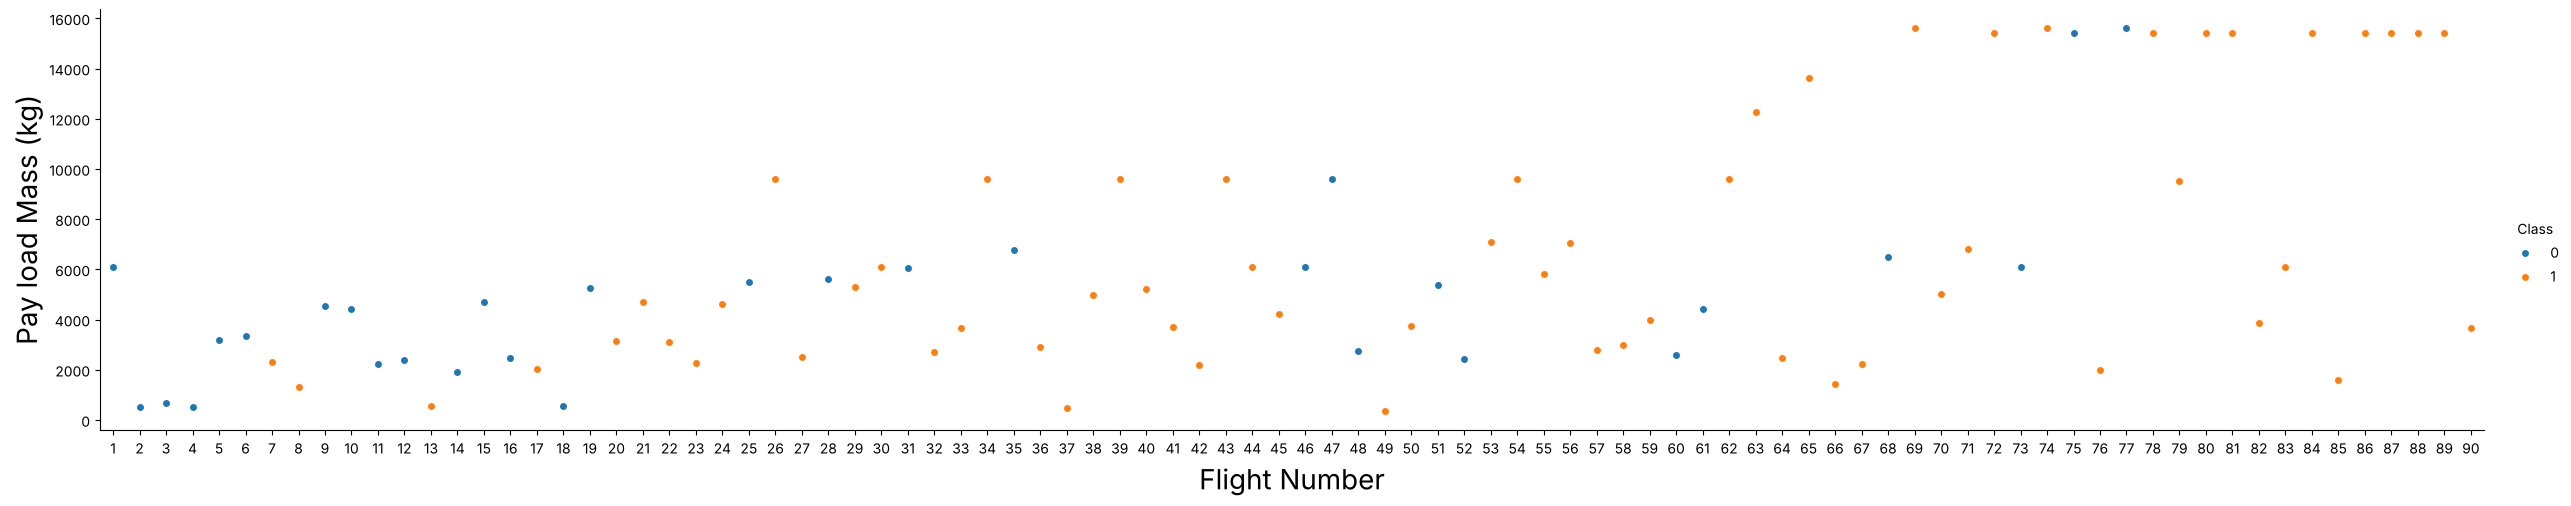

In [2]:
sns.catplot(y="PayloadMass", x="FlightNumber", hue="Class", data=df, aspect=5)
plt.xlabel("Flight Number", fontsize=20); plt.ylabel("Pay load Mass (kg)", fontsize=20)
plt.show()

## Task 1: Relationship between Flight Number and Launch Site

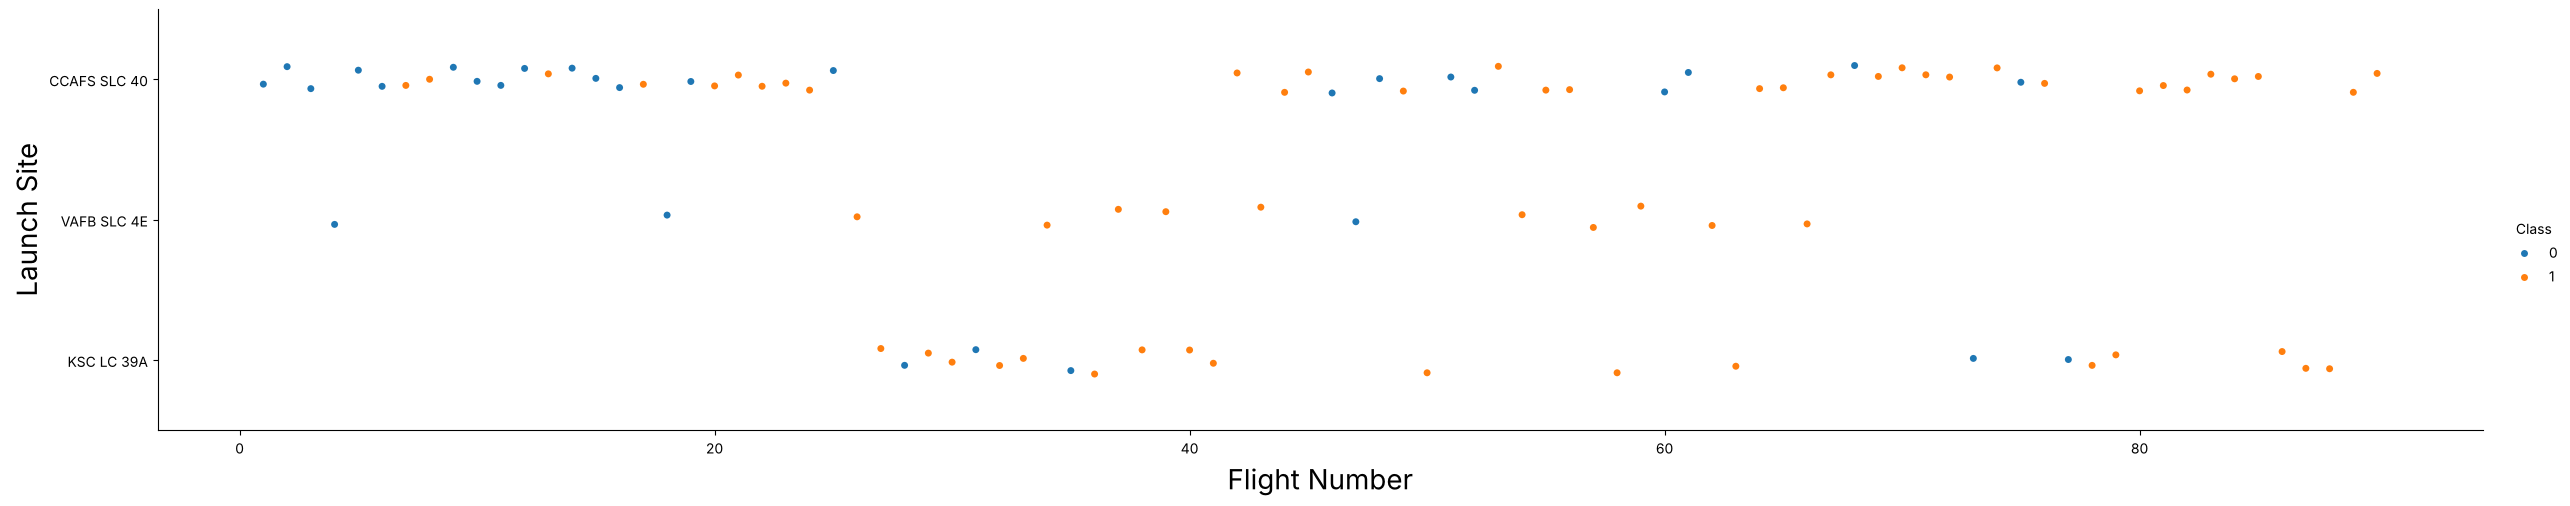

In [3]:
sns.catplot(y="LaunchSite", x="FlightNumber", hue="Class", data=df, aspect=5)
plt.xlabel("Flight Number", fontsize=20); plt.ylabel("Launch Site", fontsize=20)
plt.show()

Later flights at every site are mostly successful; CCAFS SLC 40 hosts most launches including the early failures.

## Task 2: Relationship between Payload Mass and Launch Site

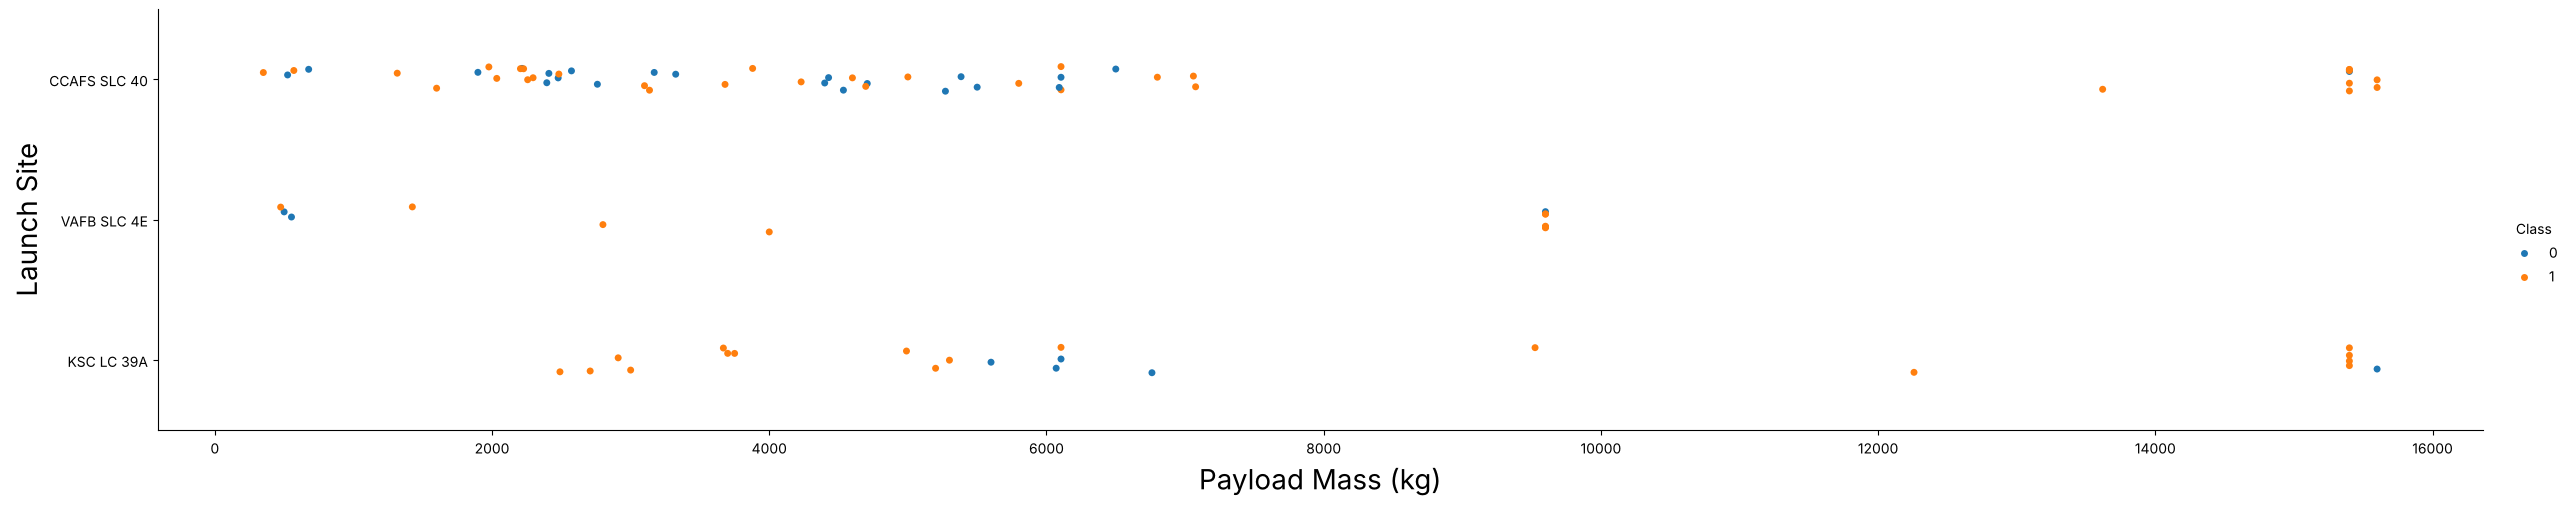

In [4]:
sns.catplot(y="LaunchSite", x="PayloadMass", hue="Class", data=df, aspect=5)
plt.xlabel("Payload Mass (kg)", fontsize=20); plt.ylabel("Launch Site", fontsize=20)
plt.show()

VAFB SLC 4E launched no heavy payloads (> 10,000 kg). Heavy payloads from CCAFS/KSC mostly landed.

## Task 3: Success rate of each orbit type

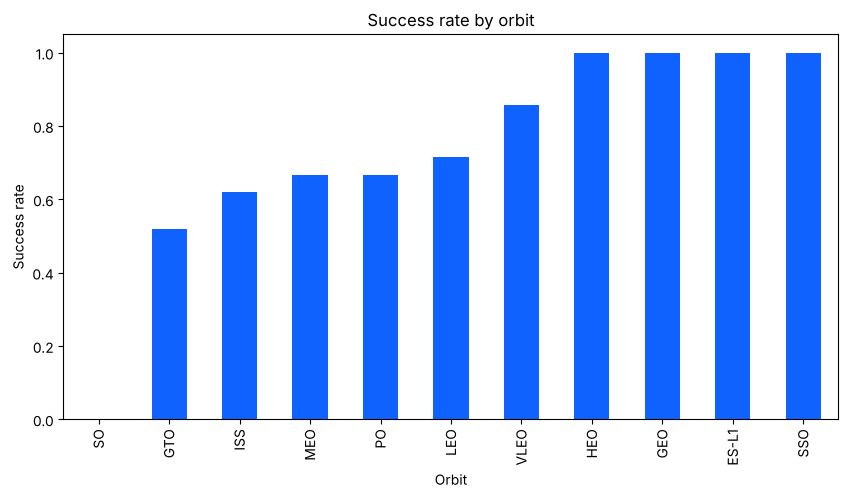

Orbit
SO       0.000000
GTO      0.518519
ISS      0.619048
MEO      0.666667
PO       0.666667
LEO      0.714286
VLEO     0.857143
HEO      1.000000
GEO      1.000000
ES-L1    1.000000
SSO      1.000000
Name: Class, dtype: float64

In [5]:
orbit_rate = df.groupby("Orbit")["Class"].mean().sort_values()
orbit_rate.plot(kind="bar", color="#0F62FE", figsize=(10, 5))
plt.ylabel("Success rate"); plt.xlabel("Orbit"); plt.title("Success rate by orbit")
plt.show()
orbit_rate

ES-L1, GEO, HEO and SSO: 100% (very few launches); GTO is the hardest (52%); SO 0% (1 launch).

## Task 4: Relationship between Flight Number and Orbit type

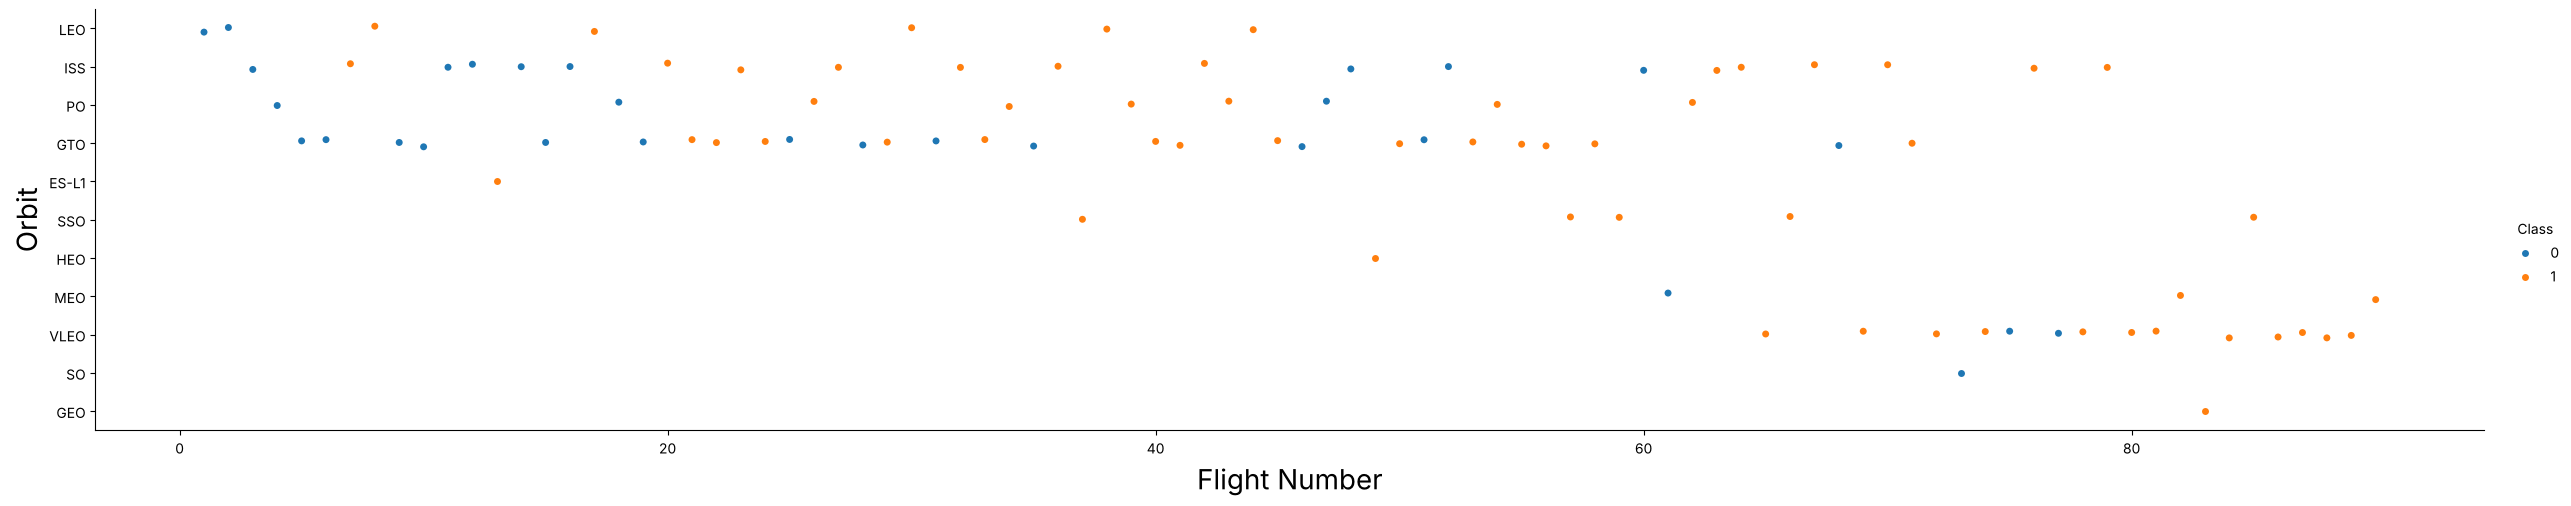

In [6]:
sns.catplot(y="Orbit", x="FlightNumber", hue="Class", data=df, aspect=5)
plt.xlabel("Flight Number", fontsize=20); plt.ylabel("Orbit", fontsize=20)
plt.show()

In LEO, success appears related to the number of flights; in GTO there is no clear relationship.

## Task 5: Relationship between Payload Mass and Orbit type

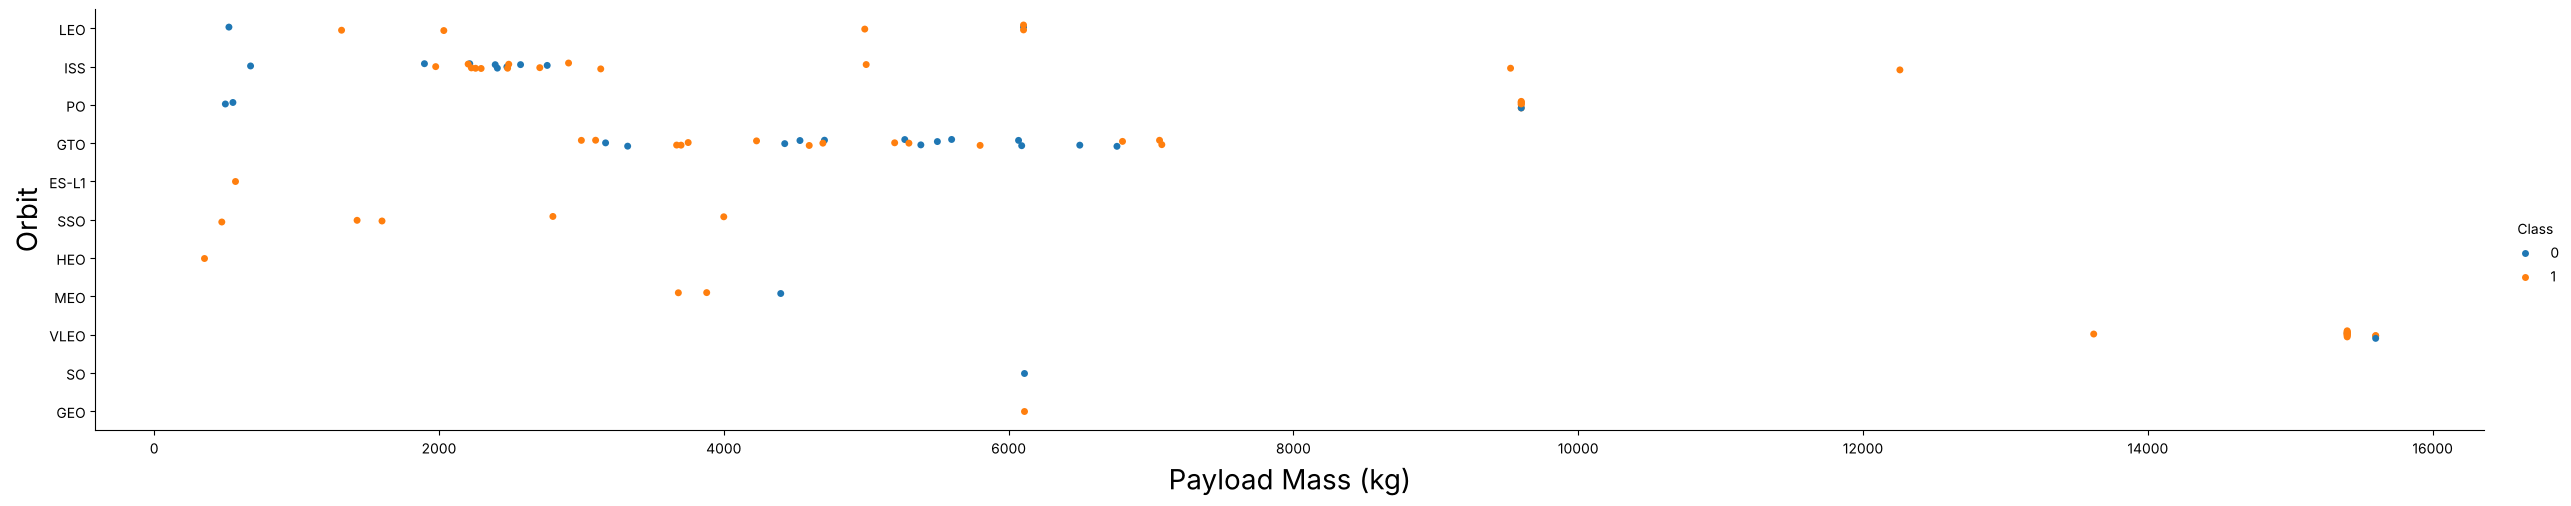

In [7]:
sns.catplot(y="Orbit", x="PayloadMass", hue="Class", data=df, aspect=5)
plt.xlabel("Payload Mass (kg)", fontsize=20); plt.ylabel("Orbit", fontsize=20)
plt.show()

Heavy payloads land more often for Polar, LEO and ISS; GTO mixes positive and negative outcomes.

## Task 6: Launch success yearly trend

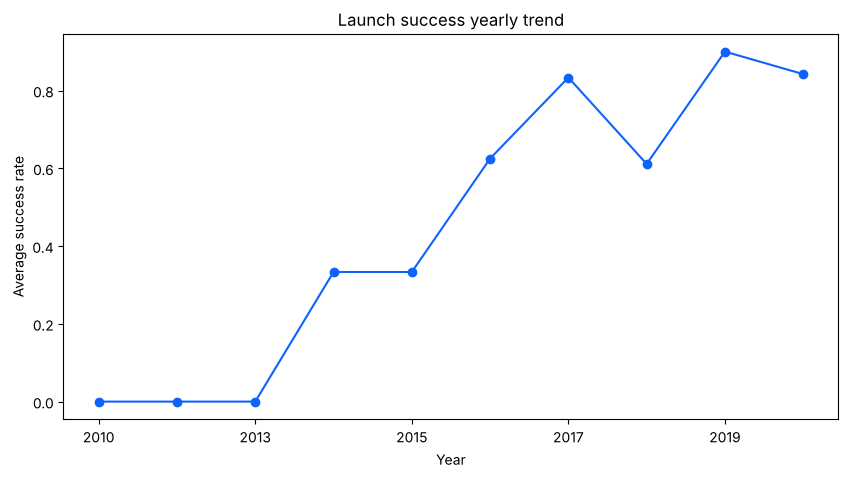

Year
2010    0.000000
2012    0.000000
2013    0.000000
2014    0.333333
2015    0.333333
2016    0.625000
2017    0.833333
2018    0.611111
2019    0.900000
2020    0.842105
Name: Class, dtype: float64

In [8]:
def Extract_year(dates):
    return [d.split("-")[0] for d in dates]
df["Year"] = Extract_year(df["Date"])
yearly = df.groupby("Year")["Class"].mean()
yearly.plot(kind="line", marker="o", color="#0F62FE", figsize=(10, 5))
plt.ylabel("Average success rate"); plt.title("Launch success yearly trend")
plt.show()
yearly

The success rate has kept increasing since 2013 (dip in 2018) up to ~84–90% in 2019–2020.

## Extra insight: landing hardware, booster reuse and Block

In [9]:
for col in ["Legs", "GridFins", "Reused", "Block"]:
    print(df.groupby(col)["Class"].agg(["mean", "count"]).round(3), "\n")

        mean  count
Legs               
False  0.053     19
True   0.831     71 

           mean  count
GridFins              
False     0.100     20
True      0.829     70 

         mean  count
Reused              
False   0.585     53
True    0.784     37 

        mean  count
Block              
1.0    0.211     19
2.0    1.000      6
3.0    0.733     15
4.0    0.545     11
5.0    0.846     39 



## Features Engineering

In [10]:
features = df[['FlightNumber', 'PayloadMass', 'Orbit', 'LaunchSite', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial']]
features.head()

,FlightNumber,PayloadMass,Orbit,LaunchSite,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial
0,1,6104.959412,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0003
1,2,525.000000,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0005
2,3,677.000000,ISS,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0007
3,4,500.000000,PO,VAFB SLC 4E,1,False,False,False,NaN,1.0,0,B1003
4,5,3170.000000,GTO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B1004


## Task 7: Create dummy variables for categorical columns

In [11]:
features_one_hot = pd.get_dummies(features, columns=['Orbit', 'LaunchSite', 'LandingPad', 'Serial'])
features_one_hot.head()

,FlightNumber,PayloadMass,Flights,GridFins,Reused,Legs,Block,ReusedCount,Orbit_ES-L1,Orbit_GEO,...,Serial_B1048,Serial_B1049,Serial_B1050,Serial_B1051,Serial_B1054,Serial_B1056,Serial_B1058,Serial_B1059,Serial_B1060,Serial_B1062
0,1,6104.959412,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
1,2,525.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
2,3,677.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
3,4,500.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
4,5,3170.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False


## Task 8: Cast all numeric columns to float64

In [12]:
features_one_hot = features_one_hot.astype('float64')
print(features_one_hot.shape)   # (90, 80)
features_one_hot.to_csv('data/dataset_part_3.csv', index=False)

(90, 80)
